# Week 7 Day 2: Loss and Accuracy Visualization

Plot training history loss and accuracy curves over epochs.

c:\Users\harsh\Music\AI_ML_HW\.venv312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


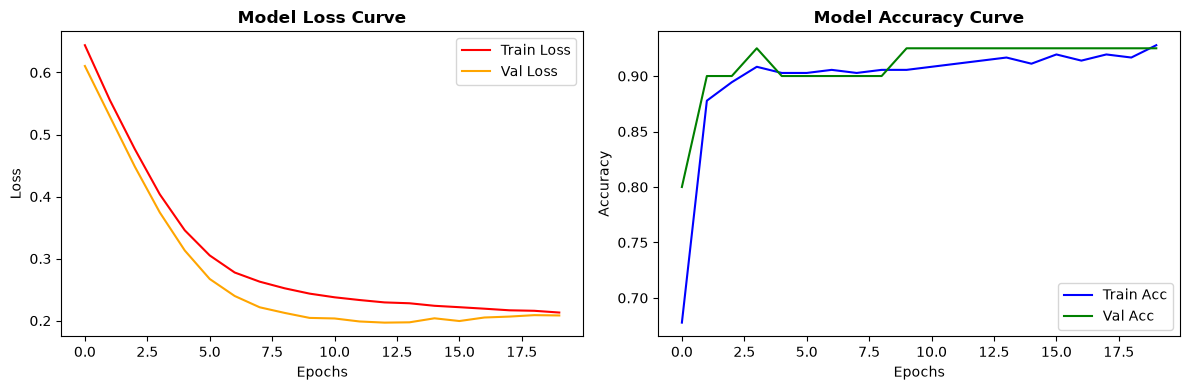

Chart saved at: saved_charts\Day2_Loss_Accuracy_Curves.png


In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

# Ensure directory exists
output_dir = "saved_charts"
os.makedirs(output_dir, exist_ok=True)

# 1. Data & Model
X, y = make_classification(n_samples=500, n_features=6, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=20, batch_size=16, validation_split=0.1, verbose=0)

# 2. Plot Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='Train Loss', color='red')
axes[0].plot(history.history['val_loss'], label='Val Loss', color='orange')
axes[0].set_title('Model Loss Curve', fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Acc', color='blue')
axes[1].plot(history.history['val_accuracy'], label='Val Acc', color='green')
axes[1].set_title('Model Accuracy Curve', fontweight='bold')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
chart_path = os.path.join(output_dir, "Day2_Loss_Accuracy_Curves.png")
plt.savefig(chart_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Chart saved at: {chart_path}")